Error processing embryo 24_6: [Errno 2] No such file or directory: '/Users/rikoyoshimi/Desktop/python/gph_pn_distance/data/24/Image 3-5_allspots.csv'
>> Stage III Summary: n = 13, Median = 7.25 hours


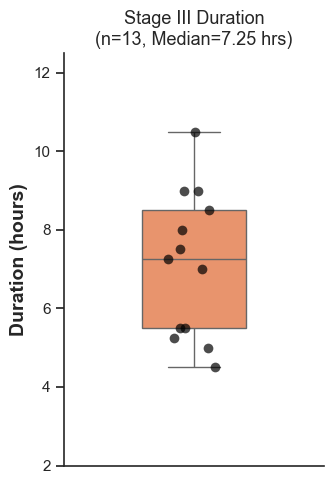

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def calculate_stage3_duration(pos_csv, radius_df, embryo_id, nebd_frame, interval_min):
    """
    Process TrackMate tracking data and radius measurements to calculate 
    the duration of Stage III (from Stage III onset to NEBD) for a single embryo.
    """
    # 1. Load TrackMate position data
    df_pos = pd.read_csv(pos_csv, skiprows=[1, 2, 3])
    pivot_pos = df_pos.pivot(index='FRAME', columns='TRACK_ID', values=['POSITION_X', 'POSITION_Y', 'POSITION_Z'])
    
    # Calculate 3D distance between pronuclei
    dist_3d = np.sqrt(
        (pivot_pos['POSITION_X'][0] - pivot_pos['POSITION_X'][1])**2 +
        (pivot_pos['POSITION_Y'][0] - pivot_pos['POSITION_Y'][1])**2 +
        (pivot_pos['POSITION_Z'][0] - pivot_pos['POSITION_Z'][1])**2
    )
    df_dist = pd.DataFrame({'FRAME': pivot_pos.index, 'distance_3d': dist_3d.values})
    
    # 2. Extract and merge radius data
    col_r1 = f"r_1_{embryo_id}"
    col_r2 = f"r2_{embryo_id}"
    df_rad = radius_df[['FRAME', col_r1, col_r2]].dropna().copy()
    df_rad.rename(columns={col_r1: 'r1', col_r2: 'r2'}, inplace=True)
    df_merged = pd.merge(df_dist, df_rad, on='FRAME', how='inner')
    
    # 3. Calculate thresholds for Stage III contact condition
    df_merged['contact_threshold'] = (df_merged['r1'] + df_merged['r2']) / 2
    df_merged['dynamic_margin'] = df_merged['contact_threshold'] * 0.10
    df_merged['lower_bound'] = df_merged['contact_threshold'] - df_merged['dynamic_margin']
    df_merged['upper_bound'] = df_merged['contact_threshold'] + df_merged['dynamic_margin']
    df_merged = df_merged.sort_values('FRAME')
    
    # 4. Identify Stage III frames and transition
    stages = []
    current_stage = 1
    for _, row in df_merged.iterrows():
        dist = row['distance_3d']
        ub = row['upper_bound']
        lb = row['lower_bound']
        
        if current_stage == 1:
            if dist < ub:
                current_stage = 2
                if dist < lb:
                    current_stage = 3
        
        if current_stage == 1:
            stages.append('Stage I')
        elif current_stage == 2:
            stages.append('Stage II')
        else:
            stages.append('Stage III')
        current_stage = 1
            
    df_merged['Stage'] = stages
    df_merged['Embryo_ID'] = embryo_id
    
    # 5. Calculate Stage III duration
    max_II_frame = df_merged[df_merged['Stage'] == 'Stage II']['FRAME'].max() if 'Stage II' in df_merged['Stage'].values else np.nan
    min_III_frame = df_merged[df_merged['Stage'] == 'Stage III']['FRAME'].min() if 'Stage III' in df_merged['Stage'].values else np.nan

    if not pd.isna(max_II_frame):
        duration_iii_frames = nebd_frame - max_II_frame
    elif not pd.isna(min_III_frame):
        duration_iii_frames = nebd_frame - min_III_frame
    else:
        duration_iii_frames = 0

    duration_hr = duration_iii_frames * (interval_min / 60.0)
    
    # Return as a single-row DataFrame for Stage III
    result_df = pd.DataFrame({
        'Embryo_ID': [embryo_id],
        'Stage': ['Stage III'],
        'Duration_hr': [duration_hr]
    })
    return result_df


def plot_stage3_duration(stage3_df):
    """
    Generate a publication-ready boxplot with individual data points for Stage III duration.
    """
    plt.figure(figsize=(3.5, 5))
    sns.set_theme(style="ticks", rc={"axes.linewidth": 1.2})
    
    stage3_color = '#fc8d59'
    n_count = stage3_df['Embryo_ID'].nunique()
    median_val = stage3_df['Duration_hr'].median()
    
    print(f">> Stage III Summary: n = {n_count}, Median = {median_val:.2f} hours")

    # Boxplot
    sns.boxplot(
        data=stage3_df, y='Duration_hr', 
        color=stage3_color, width=0.4, showfliers=False
    )
    
    # Individual data points (Stripplot)
    sns.stripplot(
        data=stage3_df, y='Duration_hr', 
        color='black', alpha=0.7, size=7, jitter=True
    )
    
    # Axis & Title styling
    plt.ylabel('Duration (hours)', fontsize=14, fontweight='bold')
    plt.ylim(2, stage3_df['Duration_hr'].max() + 2)
    plt.title(f'Stage III Duration\n(n={n_count}, Median={median_val:.2f} hrs)', fontsize=13)
    plt.xticks([])
    
    sns.despine()
    plt.tight_layout()
    plt.show()